# 03 · Domain adaptation, distillation and multi-task learning

In [1]:
import json, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from src.plotting import apply_style, hbar_groups, SERIES, MUTED, TEXT_SECONDARY
from src.preprocess import TextPreprocessor

apply_style()
pd.set_option("display.precision", 3)

def metrics(name):
    with open(os.path.join(ROOT, "results", "metrics", f"{name}.json"), encoding="utf-8") as f:
        return json.load(f)

def split(task, name):
    return TextPreprocessor.load_jsonl(os.path.join(ROOT, "data", "processed", task, f"{name}.jsonl"))

## Domain-adaptive pre-training (DAPT) and the pooler control

Masked-LM continued pre-training lowers held-out perplexity, but the classifier result depends on a second factor: BERT's pooler layer. It is pretrained for next-sentence prediction and stays frozen under LoRA. A 2 x 2 design (encoder x pooler), three seeds per cell, separates the two effects.

In [2]:
dapt = metrics("dapt")
abl = metrics("classification_ablation")
cells = {
    ("bert-base-uncased", "pretrained pooler"): abl["runs"]["lora_r16"],
    ("bert-base-uncased", "random pooler"): [metrics(f"classification_control_random_pooler_lora_s{s}") for s in (42, 7, 1234)],
    ("DAPT encoder", "pretrained pooler"): [metrics(n) for n in ("classification_dapt_bert-base-uncased_lora",
                                                                "classification_dapt_lora_s7", "classification_dapt_lora_s1234")],
    ("DAPT encoder", "random pooler"): [metrics(f"classification_dapt_random_pooler_s{s}") for s in (42, 7, 1234)],
}
grid = pd.DataFrame([{"encoder": e, "pooler": p,
                      "test acc %": np.mean([100 * r["test"]["accuracy"] for r in runs]),
                      "challenge acc %": np.mean([100 * r["challenge"]["accuracy"] for r in runs]),
                      "challenge std": np.std([100 * r["challenge"]["accuracy"] for r in runs])}
                     for (e, p), runs in cells.items()])
print(f"Held-out masked-token perplexity: {dapt['perplexity_before']:.2f} -> {dapt['perplexity_after']:.2f}")
grid

Held-out masked-token perplexity: 15.54 -> 11.22


,encoder,pooler,test acc %,challenge acc %,challenge std
0,bert-base-uncased,pretrained pooler,97.619,63.333,9.813
1,bert-base-uncased,random pooler,98.413,83.333,0.000
2,DAPT encoder,pretrained pooler,92.857,61.111,5.666
3,DAPT encoder,random pooler,99.206,87.778,4.157


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


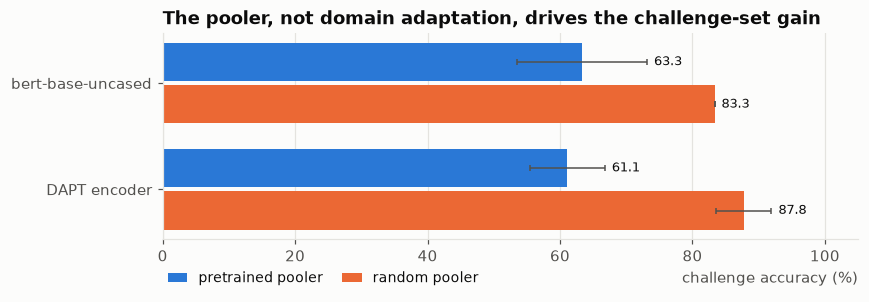

In [3]:
encoders = ["bert-base-uncased", "DAPT encoder"]
pick = lambda p, col: [grid[(grid.encoder == e) & (grid.pooler == p)][col].item() for e in encoders]
fig, ax = plt.subplots(figsize=(8, 2.9))
hbar_groups(ax, encoders, {p: pick(p, "challenge acc %") for p in ("pretrained pooler", "random pooler")},
            errors={p: pick(p, "challenge std") for p in ("pretrained pooler", "random pooler")},
            xlabel="challenge accuracy (%)", xlim=(0, 105))
ax.set_title("The pooler, not domain adaptation, drives the challenge-set gain")
fig.tight_layout()

## Knowledge distillation: roberta-base teacher -> distilbert student

,params (M),test acc %,challenge acc %,latency ms
model,,,,
teacher,124.648,95.238,86.667,0.800
student_hard_labels,66.956,100.000,83.333,0.451
student_distilled,66.956,100.000,80.000,0.400


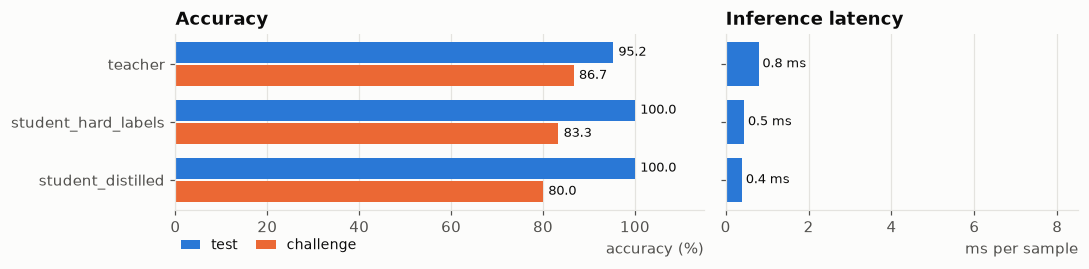

In [4]:
dist = metrics("distillation")
dt = pd.DataFrame([{"model": r["model"], "params (M)": r["total_params"] / 1e6, "test acc %": 100 * r["test"]["accuracy"],
                    "challenge acc %": 100 * r["challenge"]["accuracy"],
                    "latency ms": r["test"]["latency_ms_per_sample"]} for r in dist]).set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), gridspec_kw={"width_ratios": [3, 2]})
hbar_groups(axes[0], list(dt.index), {"test": dt["test acc %"].tolist(), "challenge": dt["challenge acc %"].tolist()},
            xlabel="accuracy (%)", xlim=(0, 115))
axes[0].set_title("Accuracy")
hbar_groups(axes[1], list(dt.index), {"GPU latency": dt["latency ms"].tolist()}, fmt="{:.1f} ms", xlabel="ms per sample", xlim=(0, 8.5))
axes[1].set_yticklabels([])
axes[1].set_title("Inference latency")
fig.tight_layout()
dt

The distilled student is no better than the student trained on hard labels; the gap is well inside the confidence intervals. With 102 training sentences the teacher's soft targets add little information.

## Multi-task shared encoder vs single-task models

,multi-task,multi-task std,single-task,single-task std
classification macro-F1 (challenge),0.905,0.064,0.850,0.062
NER strict span-F1,0.784,0.090,0.736,0.035
QA token F1,0.675,0.063,0.729,0.031


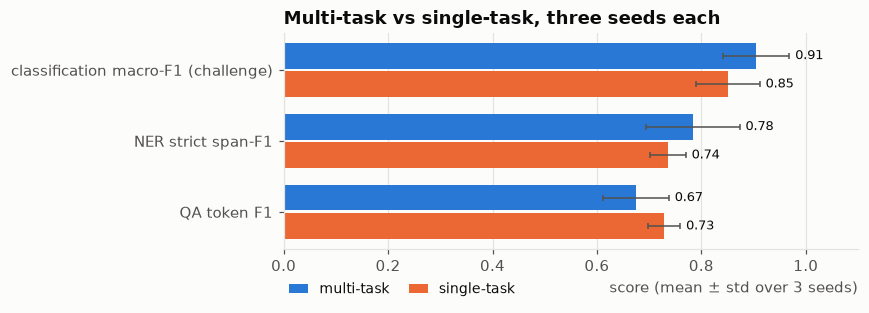

In [5]:
mt = metrics("multitask")
cols = {"classification macro-F1 (challenge)": ("classification_challenge", "macro_f1"),
        "NER strict span-F1": ("ner", "f1"), "QA token F1": ("qa", "f1")}
single = {"classification_challenge": "single_classification", "ner": "single_ner", "qa": "single_qa"}
def seed_values(run, task, key):
    return [r[task][key] for r in mt[run]]
mtab = pd.DataFrame({
    "multi-task": [np.mean(seed_values("multitask", t, k)) for t, k in cols.values()],
    "multi-task std": [np.std(seed_values("multitask", t, k)) for t, k in cols.values()],
    "single-task": [np.mean(seed_values(single[t], t, k)) for t, k in cols.values()],
    "single-task std": [np.std(seed_values(single[t], t, k)) for t, k in cols.values()],
}, index=list(cols))
fig, ax = plt.subplots(figsize=(8, 3.0))
hbar_groups(ax, list(mtab.index), {c: mtab[c].tolist() for c in ("multi-task", "single-task")},
            errors={c: mtab[f"{c} std"].tolist() for c in ("multi-task", "single-task")},
            fmt="{:.2f}", xlabel="score (mean ± std over 3 seeds)", xlim=(0, 1.1))
ax.set_title("Multi-task vs single-task, three seeds each")
fig.tight_layout()
mtab